# Fitting IRAS 07546+3928 with JNesty on the GPU

This notebook fits one real spectrum with the GPU-native side of GalSpec: JAX
models (`galspec.jax_models`) sampled by **JNesty** (`galspec.jnesty_fit`). It is
the notebook form of `fit_iras07546_jax.py`; the script is what to use in a batch
pipeline, the notebook is for looking at what happens.

## What is fitted

The **whole optical spectrum** of the quasar **IRAS 07546+3928** (z = 0.0953),
3680-7500 A in the rest frame -- 83 681 pixels. All of it is fitted at once, so
the continuum and the lines are constrained by the same posterior:

| wavelength | what | model |
| --- | --- | --- |
| 4102 A | H-delta | narrow + **two** broad Gaussians |
| 4340 A | H-gamma | narrow + **two** broad Gaussians |
| 4861 A | H-beta | narrow + **two** broad Gaussians |
| 6563 A | H-alpha | narrow + **two** broad Gaussians |
| 4959 / 5007 A | [O III] | narrow core + one broad wing |
| 6548 / 6584 A | [N II] | narrow, doublet ratio 2.96 (atomic physics) |
| 6716 / 6731 A | [S II] | narrow, **both peaks free** (the ratio is a density diagnostic) |
| 6300 / 6364 A | [O I] | narrow, doublet ratio 3.00 |
| 3970, 3889, 3835, 3770 A | H-epsilon, H8, H9, H11 | single narrow Gaussian |
| 4686, 4363, 3869 A | He II, [O III], [Ne III] | single narrow Gaussian |
| 3727, 7136, 7320 A | [O II], [Ar III], [O II] | single narrow Gaussian |
| all | continuum | power law + Fe II template |

## How it is fitted

* **No least-squares step.** Nothing is optimised before nested sampling starts,
  so the priors cannot inherit a preliminary answer. JNesty walks the prior
  directly.
* **No instrumental smoothing.** At 0.046 A per pixel the spectrum grossly
  oversamples the spectrograph: R = 2000 means ~150 km/s of instrument, while the
  narrow lines here are ~700 km/s. So the model is *not* convolved, exactly as in
  `wrk_sagan_iras07546.ipynb`; the fitted narrow width is the observed one.
* **Wide priors, taken from the data.** Line peaks from invisible to 3x the
  brightest pixel (log-uniform); broad components 300-8000 and 800-25000 km/s.
  Section 4 shows the prior spread against the data.
* **Physical ties.** Every narrow line shares one velocity shift and one width
  (measured from [O III]); the two broad components are each shared across all
  four Balmer lines. 38 free numbers therefore describe twenty components.

Runtime: 30-45 minutes on one GPU with `nlive=400, dlogz=0.01` (this run:
33 min, 84 994 iterations). For a quick look
set `NLIVE = 200` and `DLOGZ = 0.1` in the settings cell and expect wider error
bars.


## 1. Imports and settings

Everything a user might want to change is in the next cell: the redshift, the
extinction, the wavelength window, and the two sampler settings.


In [1]:
import sys
import time
import warnings
from pathlib import Path

# The repository is used straight from a checkout (it is not installed), so put
# its root on the path: this notebook lives in <repo>/example/.
REPO = Path.cwd()
if not (REPO / "galspec").is_dir():
    REPO = REPO.parent
sys.path.insert(0, str(REPO))

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import median_filter

import galspec
from galspec import jax_models as jxm
from galspec.jnesty_fit import JNesty_Fit, jax_devices_summary
from galspec.jnesty_fit_io import save_jnesty_fit_to_fits, load_jnesty_fit_from_fits
from galspec.utils import line_wave_dict as LINE_WAVE

warnings.simplefilter("ignore")
%matplotlib inline


In [2]:
# ---- how the fit is set up -------------------------------------------------
EXAMPLE_DIR = Path.cwd()
if not (EXAMPLE_DIR / "data" / "ir07546sed.fits").exists():
    EXAMPLE_DIR = REPO / "example"          # run from somewhere else
DATA_FILE = EXAMPLE_DIR / "data" / "ir07546sed.fits"

REDSHIFT = 0.0953          # NASA/IPAC value for IRAS 07546+3928
E_BV = 0.176               # Galactic extinction towards it (Schlafly & Finkbeiner)
WAVE_MIN, WAVE_MAX = 3680.0, 7500.0   # rest frame: the whole optical spectrum

ERROR_FRACTION = 0.005     # floor on the pixel-to-pixel noise
SYSTEMATIC_FRACTION = 0.030  # flux calibration, Fe II template, hot-star mismatch
MASK_WINDOWS = [(3905.0, 3995.0),    # Ca II H+K absorption from the host galaxy
                (5840.0, 5930.0),    # Na D absorption (He I 5876 sits inside it)
                (6860.0, 7100.0)]    # residual O2 A-band at 7600 A observed

NLIVE = 400                # live points the sampler keeps
DLOGZ = 0.01               # stop when < 1% of the evidence may remain unseen

BALMER_NAMES = ("Halpha", "Hbeta", "Hgamma", "Hdelta")
SINGLE_LINES = ("HeII", "OIII4363", "NeIII", "OII3727", "ArIII", "OII7325",
                "Hepsilon", "H8", "H9", "H11")
EXTRA_LINES = {"NeIII_3869": 3868.76,      # not in line_wave_dict
               "ArIII_7136": 7135.79,
               "OII_7325": 7325.0,         # blend of the 7318.9/7330.2 pair
               "Hepsilon_3970": 3970.07,   # the higher Balmer lines
               "H8_3889": 3889.05,
               "H9_3835": 3835.39,         # n = 9 -> 2
               "H11_3770": 3770.63}        # n = 11 -> 2


## 2. The data

The FITS file that ships with GalSpec has flux only, no uncertainty, so the
uncertainty is measured from the data: subtract a running median, take the median
absolute deviation in a 30 A window (which ignores the few pixels belonging to
emission lines), convert to a Gaussian sigma, and smooth. That gives a
wavelength-dependent noise level, shown in the lower panel below, which rises
from ~0.3% of the flux at 4700 A to ~4% at the red end.

A 3% **systematic** term is added in quadrature on top. It stands for everything
the model does not describe exactly -- flux calibration, the shape of the Fe II
template, departures from a pure power law -- and without it a Bayesian fit would
chase pixel noise in the continuum.

Three windows are down-weighted (grey bands) because the model deliberately does
not describe them: the host galaxy's **Ca II H+K** absorption at 3934/3968 A, the
**Na D** absorption at 5890 A (which also hides He I 5876), and the residual
**O2 A-band** absorption that the SDSS pipeline left around 7600 A observed
(6860-7100 A in the rest frame). Masking that last one matters: it alone carried
a quarter of the total chi-square in a first version of this fit.

Units: fluxes in `1e-14 erg/s/cm2/A`, velocities in km/s.


In [3]:
from astropy.io import fits
from extinction import ccm89, remove


def estimate_error(flux, window=751):
    """Per-pixel uncertainty measured from the spectrum itself.

    Subtract a running median (about 30 A), take the median of the absolute
    remainder in the same window -- which ignores the few pixels that belong to
    emission lines -- divide by 0.6745 to turn it into a Gaussian sigma, and
    smooth over a few hundred A.  A 3% systematic term is then added in
    quadrature: it stands for flux calibration, the shape of the Fe II template
    and any departure from a pure power law.
    """
    baseline = median_filter(flux, size=window, mode="nearest")
    scatter = median_filter(np.abs(flux - baseline), size=window, mode="nearest") / 0.6745
    scatter = median_filter(scatter, size=4 * window + 1, mode="nearest")
    return np.hypot(np.maximum(scatter, ERROR_FRACTION * np.abs(flux)),
                    SYSTEMATIC_FRACTION * np.abs(flux))


def mask_regions(wave, error):
    """Down-weight the windows the model does not describe."""
    error = error.copy()
    for lo, hi in MASK_WINDOWS:
        error[(wave > lo) & (wave < hi)] *= 3.0
    return error


def load_spectrum():
    """Dereddened, rest-frame spectrum between WAVE_MIN and WAVE_MAX."""
    with fits.open(DATA_FILE) as hdul:
        header = hdul[0].header
        flux_array = np.asarray(hdul[0].data, dtype=float) * 1e14
    wave_array = header["CRVAL1"] + header["CD1_1"] * np.arange(flux_array.size)

    flux_array = remove(ccm89(wave_array, E_BV, r_v=3.1, unit="aa"), flux_array)  # Milky Way
    wave_array = wave_array / (1.0 + REDSHIFT)                      # observed -> rest frame

    use = (wave_array > WAVE_MIN) & (wave_array < WAVE_MAX)
    wave_array, flux_array = wave_array[use], flux_array[use]
    return wave_array, flux_array, mask_regions(wave_array, estimate_error(flux_array))


wave, flux, error = load_spectrum()
print(f"{wave.size:,} pixels, {wave[0]:.0f}-{wave[-1]:.0f} A rest frame, "
      f"{np.median(np.diff(wave)):.4f} A per pixel")
print(f"peak flux {flux.max():.2f}, line-free level {np.percentile(flux, 15):.2f}  "
      "[1e-14 erg/s/cm2/A]")
for lo, hi in ((3800, 4200), (4200, 5000), (5000, 6000), (6000, 7000), (7000, 7500)):
    sel = (wave > lo) & (wave < hi)
    print(f"  {lo}-{hi} A: median flux {np.median(flux[sel]):5.2f}, "
          f"median error {np.median(error[sel]):5.3f} "
          f"({100*np.median(error[sel]/flux[sel]):4.1f}% of the flux)")


83,681 pixels, 3680-7500 A rest frame, 0.0456 A per pixel
peak flux 4.33, line-free level 0.43  [1e-14 erg/s/cm2/A]
  3800-4200 A: median flux  0.89, median error 0.033 ( 3.5% of the flux)
  4200-5000 A: median flux  0.81, median error 0.026 ( 3.1% of the flux)
  5000-6000 A: median flux  0.56, median error 0.019 ( 3.2% of the flux)
  6000-7000 A: median flux  0.50, median error 0.018 ( 3.4% of the flux)
  7000-7500 A: median flux  0.41, median error 0.018 ( 4.4% of the flux)


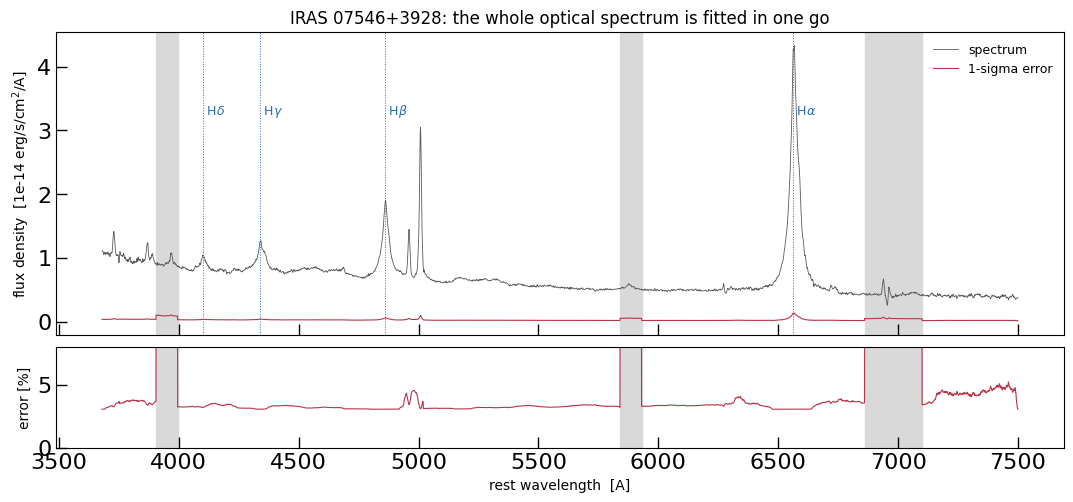

In [4]:
fig, axs = plt.subplots(2, 1, figsize=(13.0, 5.4), sharex=True,
                        gridspec_kw={"height_ratios": [3.0, 1.0], "hspace": 0.06})
step = slice(None, None, 5)
axs[0].plot(wave[step], flux[step], color="0.35", lw=0.6, label="spectrum")
axs[0].plot(wave[step], error[step], color="#b5364a", lw=0.8, label="1-sigma error")
for (lo, hi) in MASK_WINDOWS:
    axs[0].axvspan(lo, hi, color="0.85", zorder=0)
    axs[1].axvspan(lo, hi, color="0.85", zorder=0)
top = np.percentile(flux, 99.5)
for centre, text in ((LINE_WAVE["Hdelta"], "H$\\delta$"),
                     (LINE_WAVE["Hgamma"], "H$\\gamma$"),
                     (LINE_WAVE["Hbeta"], "H$\\beta$"),
                     (LINE_WAVE["Halpha"], "H$\\alpha$")):
    axs[0].axvline(centre, color="#2b6cb0", lw=0.7, ls=":")
    axs[0].text(centre, top, " " + text, fontsize=9, color="#2b6cb0")
axs[0].set_ylabel("flux density  [1e-14 erg/s/cm$^2$/A]")
axs[0].set_title("IRAS 07546+3928: the whole optical spectrum is fitted in one go")
axs[0].legend(fontsize=9, frameon=False, loc="upper right")
axs[1].plot(wave[step], 100*error[step]/np.abs(flux[step]), color="#b5364a", lw=0.8)
axs[1].set_ylabel("error [%]")
axs[1].set_xlabel("rest wavelength  [A]")
axs[1].set_ylim(0, 8)
plt.tight_layout()


## 3. The model

Twenty components, added together:

1. a **power-law continuum** anchored at 5500 A -- this is what fixes the
   continuum level and slope from the line-free regions of the whole spectrum;
2. an **Fe II template** -- the forest of iron lines that fakes a broad bump
   blueward of H-beta and is routinely mistaken for continuum;
3. **H-alpha, H-beta, H-gamma, H-delta**, each a `Line_MultiGauss` with three
   Gaussians: a narrow core (`amp_c`, `dv_c`, `sigma_c`), a broad component
   (`amp_w0`, `dv_w0`, `sigma_w0`) and a second, broader one (`amp_w1`, `dv_w1`,
   `sigma_w1`). The wind amplitudes are *ratios to the core amplitude*, which is
   how the GalSpec models are written;
4. **[O III] 4959/5007** as a doublet with a narrow core and one broad wing;
5. **[N II], [S II], [O I]** doublets, plus single narrow Gaussians for **He II
   4686, [O III] 4363, [Ne III] 3869, [O II] 3727, [Ar III] 7136, [O II] 7320**
   and the higher Balmer lines **H-epsilon 3970, H8 3889, H9 3835, H11 3770**.
   The last four carry a narrow core only: they are strong enough to matter at
   the blue end, but their broad wings are weak and would not be constrained that
   far down the Balmer series.

The ties are what make this affordable:

* one `dv_c` and one `sigma_c` for **all** narrow lines, taken from the [O III]
  core (forbidden lines come from the same low-density gas);
* `dv_w0`/`sigma_w0` shared by the four Balmer lines, and `dv_w1`/`sigma_w1`
  likewise: the two broad components are separate physical structures, so they
  get separate kinematics, but each is common to the four lines;
* doublet ratios fixed by atomic physics for [O III] (2.98), [N II] (2.96) and
  [O I] (3.00) -- but **not** for [S II], whose 6716/6731 ratio is a density
  diagnostic and therefore stays free.

Note there is no `* multi` polynomial here: the reference notebook multiplies one
in because it uses a least-squares fitter with no error model, whereas here the
3% systematic floor already absorbs flux-calibration error, and a high-order
polynomial on top of a power law plus an Fe II template would be strongly
degenerate with both.


In [5]:
class _TieFrom:
    """Copy one parameter of another submodel (the plain-Gaussian case)."""

    def __init__(self, submodel, parameter):
        self.submodel = submodel
        self.parameter = parameter

    def __call__(self, model):
        return getattr(model[self.submodel], self.parameter)


def _tie_fn(backend, name):
    """``tie`` helpers of either backend (``jxm.tie.*`` or ``galspec.*``)."""
    return getattr(getattr(backend, "tie", backend), name)


def _power_law(backend):
    """The power-law class of either backend."""
    if backend is jxm:
        return jxm.PowerLaw1D
    from astropy.modeling import models as astro_models
    return astro_models.PowerLaw1D


def free_qualified_names(model):
    """``Submodel.parameter`` spelling of every free parameter."""
    pairs = zip(model.param_names, model.qualified_param_names)
    free = set(model.free_param_names)
    return [q for flat, q in pairs if flat in free]


In [6]:
def build_model(backend=jxm):
    """The full model, with three Gaussians per Balmer line.

    ``backend`` is either ``galspec.jax_models`` (what the fit uses) or
    ``galspec`` itself (the astropy equivalents).  Both expose the same
    constructors, tie helpers and parameter names, so one function builds the
    model twice: once to fit, once to hand to ``galspec.plot.plot_fit``.

    Each Balmer line is a ``Line_MultiGauss`` with ``n_components=3``: a narrow
    core (amp_c, dv_c, sigma_c), a broad component (amp_w0, dv_w0, sigma_w0) and
    a second, broader one (amp_w1, dv_w1, sigma_w1).  The wind amplitudes are
    ratios to the core amplitude, which is how the GalSpec models are written.
    No convolution is applied: see the introduction.
    """
    # -- continuum: a power law anchored at 5500 A, plus the iron pseudo-continuum --
    continuum = _power_law(backend)(amplitude=0.55, x_0=5500.0, alpha=1.0,
                                    fixed={"x_0": True}, name="Continuum")
    iron = backend.IronTemplate(amplitude=0.2, stddev=3000.0, z=0.0, name="FeII")
    iron.z.fixed = True
    iron.stddev.fixed = True      # degenerate with the continuum slope

    # -- Balmer lines: narrow core + two broad Gaussians each -------------------
    def balmer(name, wavec, amp_c, amp_w0):
        return backend.Line_MultiGauss(
            n_components=3, amp_c=amp_c, dv_c=0.0, sigma_c=700.0,
            wavec=wavec, name=name, amp_w0=amp_w0, dv_w0=0.0, sigma_w0=2400.0,
            amp_w1=0.05, dv_w1=0.0, sigma_w1=6000.0)

    halpha = balmer("Halpha", LINE_WAVE["Halpha"], 2.2, 0.28)
    hbeta = balmer("Hbeta", LINE_WAVE["Hbeta"], 0.8, 0.30)
    hgamma = balmer("Hgamma", LINE_WAVE["Hgamma"], 0.4, 0.30)
    hdelta = balmer("Hdelta", LINE_WAVE["Hdelta"], 0.2, 0.30)

    # -- forbidden lines -------------------------------------------------------
    o3 = backend.Line_MultiGauss_doublet(
        n_components=2, amp_c0=1.8, amp_c1=1.8 / 2.98, dv_c=0.0, sigma_c=700.0,
        wavec0=LINE_WAVE["OIII_5007"], wavec1=LINE_WAVE["OIII_4959"],
        name="OIII", amp_w0=0.3, dv_w0=0.0, sigma_w0=1800.0)
    n2 = backend.Line_MultiGauss_doublet(
        n_components=1, amp_c0=1.0, amp_c1=1.0 / 2.96, dv_c=0.0, sigma_c=700.0,
        wavec0=LINE_WAVE["NII_6583"], wavec1=LINE_WAVE["NII_6548"], name="NII")
    # [S II]: the two peaks stay independent -- their ratio is a density
    # diagnostic, so it has to come out of the fit rather than go in as a guess.
    s2 = backend.Line_MultiGauss_doublet(
        n_components=1, amp_c0=0.10, amp_c1=0.10, dv_c=0.0, sigma_c=700.0,
        wavec0=LINE_WAVE["SII_6716"], wavec1=LINE_WAVE["SII_6731"], name="SII")
    o1 = backend.Line_MultiGauss_doublet(
        n_components=1, amp_c0=0.05, amp_c1=0.05 / 3.0, dv_c=0.0, sigma_c=700.0,
        wavec0=LINE_WAVE["OI_6300"], wavec1=LINE_WAVE["OI_6364"], name="OI")

    # -- single narrow Gaussians ----------------------------------------------
    def narrow(name, wavec, amplitude):
        return backend.Line_Gaussian(amplitude=amplitude, dv=0.0, sigma=700.0,
                                     wavec=wavec, name=name)

    he2 = narrow("HeII", LINE_WAVE["HeII_4686"], 0.08)
    o3_4363 = narrow("OIII4363", LINE_WAVE["OIII_4363"], 0.05)
    ne3 = narrow("NeIII", EXTRA_LINES["NeIII_3869"], 0.12)
    o2_3727 = narrow("OII3727", 0.5 * (LINE_WAVE["OII_3726"] + LINE_WAVE["OII_3728"]), 0.5)
    ar3 = narrow("ArIII", EXTRA_LINES["ArIII_7136"], 0.01)
    o2_7325 = narrow("OII7325", EXTRA_LINES["OII_7325"], 0.01)
    # The higher Balmer lines matter at the blue end and get a narrow core only:
    # their broad wings are weak, and giving four more lines two broad Gaussians
    # each would not be constrained this far down the series.
    heps = narrow("Hepsilon", EXTRA_LINES["Hepsilon_3970"], 0.08)
    h8 = narrow("H8", EXTRA_LINES["H8_3889"], 0.05)
    h9 = narrow("H9", EXTRA_LINES["H9_3835"], 0.04)
    h11 = narrow("H11", EXTRA_LINES["H11_3770"], 0.04)

    model = (continuum + iron + halpha + hbeta + hgamma + hdelta
             + o3 + n2 + s2 + o1 + he2 + o3_4363 + ne3 + o2_3727 + ar3 + o2_7325
             + heps + h8 + h9 + h11)

    # -- ties: one narrow kinematics for every narrow line, [O III] as reference --
    for line in (halpha, hbeta, hgamma, hdelta, n2, s2, o1):
        line.dv_c.tied = _tie_fn(backend, "tie_MultiGauss_dv_c")("OIII")
        line.sigma_c.tied = _tie_fn(backend, "tie_MultiGauss_sigma_c")("OIII")
    for line in (he2, o3_4363, ne3, o2_3727, ar3, o2_7325, heps, h8, h9, h11):
        line.dv.tied = _TieFrom("OIII", "dv_c")
        line.sigma.tied = _TieFrom("OIII", "sigma_c")

    # -- broad components: two of them, each shared by all four Balmer lines ----
    for line in (hbeta, hgamma, hdelta):
        line.dv_w0.tied = _tie_fn(backend, "tie_MultiGauss_dv_w0")("Halpha")
        line.sigma_w0.tied = _tie_fn(backend, "tie_MultiGauss_sigma_w0")("Halpha")
        line.dv_w1.tied = _tie_fn(backend, "tie_MultiGauss_dv_w1")("Halpha")
        line.sigma_w1.tied = _tie_fn(backend, "tie_MultiGauss_sigma_w1")("Halpha")
    o3.dv_w0.tied = _TieFrom("OIII", "dv_c")   # the wing sits at the core velocity

    # -- doublet ratios fixed by atomic physics --------------------------------
    # (not [S II]: its ratio is density-sensitive and stays a free parameter)
    o3.amp_c1.tied = _tie_fn(backend, "tie_MultiGauss_doublet_ratio")("OIII", 2.98)
    n2.amp_c1.tied = _tie_fn(backend, "tie_MultiGauss_doublet_ratio")("NII", 2.96)
    o1.amp_c1.tied = _tie_fn(backend, "tie_MultiGauss_doublet_ratio")("OI", 3.00)

    return model


model = build_model(jxm)


In [7]:
print(f"{len(model.free_param_names)} free parameters "
      f"({len(model.qualified_param_names)} in total, the rest are fixed or tied):\n")
for q in free_qualified_names(model):
    print("   ", q)


38 free parameters (113 in total, the rest are fixed or tied):

    Continuum.amplitude
    Continuum.alpha
    FeII.amplitude
    Halpha.amp_c
    Halpha.amp_w0
    Halpha.dv_w0
    Halpha.sigma_w0
    Halpha.amp_w1
    Halpha.dv_w1
    Halpha.sigma_w1
    Hbeta.amp_c
    Hbeta.amp_w0
    Hbeta.amp_w1
    Hgamma.amp_c
    Hgamma.amp_w0
    Hgamma.amp_w1
    Hdelta.amp_c
    Hdelta.amp_w0
    Hdelta.amp_w1
    OIII.amp_c0
    OIII.dv_c
    OIII.sigma_c
    OIII.amp_w0
    OIII.sigma_w0
    NII.amp_c0
    SII.amp_c0
    SII.amp_c1
    OI.amp_c0
    HeII.amplitude
    OIII4363.amplitude
    NeIII.amplitude
    OII3727.amplitude
    ArIII.amplitude
    OII7325.amplitude
    Hepsilon.amplitude
    H8.amplitude
    H9.amplitude
    H11.amplitude


## 4. The priors -- broad, and justified by the data

This is the part that decides whether a fit is honest. Every range below comes
from the spectrum itself, never from a previous fit:

| what | range | why |
| --- | --- | --- |
| line peaks | 1e-3 to 3x the brightest pixel, **log-uniform** | four decades: from invisible to implausibly strong |
| broad/narrow ratio | 1e-3 to 8, log-uniform | from no broad component to one that dominates |
| narrow widths | 30-800 km/s | unresolved up to the widest known narrow-line region |
| broad component 0 | 300-8000 km/s | FWHM up to ~19000 km/s |
| broad component 1 | 800-25000 km/s | FWHM up to ~59000 km/s, for a line wing |
| continuum level | 0.2-4x the line-free windows | cannot be negative, cannot swamp the lines |
| [S II] 6716/6731 | both peaks 1e-3 to 3x peak | the ratio is measured, not assumed |

One subtlety: bounds passed in `bounds_dict` are *linear*-uniform by design, and a
linear prior over four decades would put 99% of its probability at the bright
end. Amplitudes therefore get an explicit `log_uniform` callable through
`custom_priors`, so every factor of ten is equally likely.


In [8]:
def log_uniform(lower, upper):
    """Prior that is uniform per decade between ``lower`` and ``upper``."""
    lo, hi = np.log10(lower), np.log10(upper)

    def transform(u):
        return 10.0 ** (lo + (hi - lo) * u)

    return transform


def make_priors(flux):
    """Bounds and log-uniform priors for the whole model."""
    peak = float(np.max(flux))
    continuum = float(np.percentile(flux, 15.0))
    amp = (1e-3, 3.0 * peak)      # line peaks
    ratio = (1e-3, 8.0)           # broad / narrow amplitude

    bounds = {
        "Continuum.amplitude": (0.2 * continuum, 4.0 * continuum),
        "Continuum.alpha": (-5.0, 5.0),
        "FeII.amplitude": (1e-3, 3.0 * continuum),
        "OIII.dv_c": (-1000.0, 1000.0),
        "OIII.sigma_c": (30.0, 800.0),
        "OIII.amp_c0": amp,
        "OIII.amp_w0": ratio,
        "OIII.sigma_w0": (300.0, 4000.0),
        "NII.amp_c0": amp,
        "SII.amp_c0": amp, "SII.amp_c1": amp,
        "OI.amp_c0": amp,
        "Halpha.dv_w0": (-2500.0, 2500.0),
        "Halpha.sigma_w0": (300.0, 8000.0),
        "Halpha.dv_w1": (-6000.0, 6000.0),
        "Halpha.sigma_w1": (800.0, 25000.0),
    }
    for name in BALMER_NAMES:
        bounds[f"{name}.amp_c"] = amp
        bounds[f"{name}.amp_w0"] = ratio
        bounds[f"{name}.amp_w1"] = ratio
    for name in SINGLE_LINES:
        bounds[f"{name}.amplitude"] = amp

    log_params = [n for n in bounds
                  if n.endswith(("amp_c", "amp_c0", "amp_c1", "amp_w0", "amp_w1",
                                 "amplitude"))]
    return bounds, {n: log_uniform(*bounds[n]) for n in log_params}


bounds, custom_priors = make_priors(flux)
print(f"{len(bounds)} free parameters, each with an explicit prior:")
for q in free_qualified_names(model):
    lo, hi = bounds[q]
    kind = "log" if q in custom_priors else "linear"
    print(f"  {q:22s} ({lo:9.3f}, {hi:9.3f})  {kind}-uniform")


38 free parameters, each with an explicit prior:
  Continuum.amplitude    (    0.086,     1.721)  log-uniform
  Continuum.alpha        (   -5.000,     5.000)  linear-uniform
  FeII.amplitude         (    0.001,     1.291)  log-uniform
  Halpha.amp_c           (    0.001,    12.997)  log-uniform
  Halpha.amp_w0          (    0.001,     8.000)  log-uniform
  Halpha.dv_w0           (-2500.000,  2500.000)  linear-uniform
  Halpha.sigma_w0        (  300.000,  8000.000)  linear-uniform
  Halpha.amp_w1          (    0.001,     8.000)  log-uniform
  Halpha.dv_w1           (-6000.000,  6000.000)  linear-uniform
  Halpha.sigma_w1        (  800.000, 25000.000)  linear-uniform
  Hbeta.amp_c            (    0.001,    12.997)  log-uniform
  Hbeta.amp_w0           (    0.001,     8.000)  log-uniform
  Hbeta.amp_w1           (    0.001,     8.000)  log-uniform
  Hgamma.amp_c           (    0.001,    12.997)  log-uniform
  Hgamma.amp_w0          (    0.001,     8.000)  log-uniform
  Hgamma.amp_w1      

### Does the prior cover the data?

A useful sanity check, and the reason no least-squares seed is needed: draw
parameter sets from the prior, evaluate the model for each, and look at the
spread. If the data fall inside that band, the prior contains the answer. (The
band is wide on purpose -- that is what "broad prior" means.)


In [9]:
fit = JNesty_Fit(model, wave, flux, error,
                 bounds_dict=bounds, custom_priors=custom_priors,
                 nlive=NLIVE, bound="multi", device="auto")

print(f"free parameters : {fit.ndim}")
print(f"device          : {fit.device}  [{jax_devices_summary()}]")
print(f"live points     : {fit.nlive}")


free parameters : 38
device          : gpu  [gpu:0 (19.0 GB)]
live points     : 400


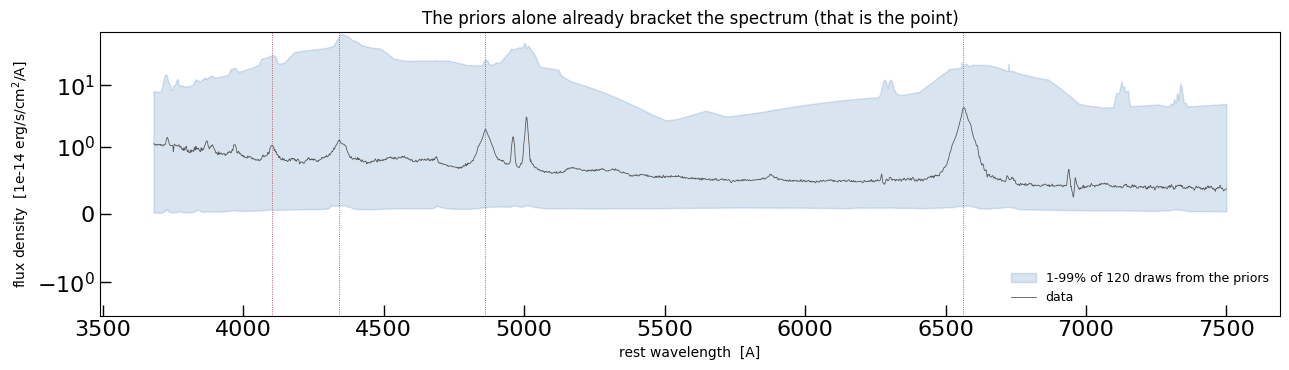

In [10]:
model.prepare(wave)
rng = np.random.default_rng(0)
u = rng.random((120, fit.ndim))
theta_prior = np.array([fit.prior_transform(row) for row in u])
draws = np.asarray(model.flux_batch(wave, theta_prior))

fig, ax = plt.subplots(figsize=(13.0, 3.8))
step = slice(None, None, 11)
ax.fill_between(wave[step], np.percentile(draws, 1, axis=0)[step],
                np.percentile(draws, 99, axis=0)[step], color="#2b6cb0",
                alpha=0.18, label="1-99% of 120 draws from the priors")
ax.plot(wave[step], flux[step], color="0.35", lw=0.6, label="data")
for centre in (LINE_WAVE["Hdelta"], LINE_WAVE["Hgamma"],
               LINE_WAVE["Hbeta"], LINE_WAVE["Halpha"]):
    ax.axvline(centre, color="#b5364a", lw=0.6, ls=":")
ax.set_yscale("symlog", linthresh=1.0)
ax.set_xlabel("rest wavelength  [A]")
ax.set_ylabel("flux density  [1e-14 erg/s/cm$^2$/A]")
ax.set_title("The priors alone already bracket the spectrum (that is the point)")
ax.legend(fontsize=9, frameon=False)
plt.tight_layout()


## 5. Run the sampler

`JNesty_Fit` compiles the log-likelihood and the prior transform with `jax.jit`,
batches likelihood evaluations on the GPU, and runs nested sampling until the
remaining evidence is below `dlogz`.

Nested sampling keeps `NLIVE` "live points" drawn from the prior and repeatedly
replaces the worst one with a point of higher likelihood: the volume shrinks, the
likelihood rises, and the integral of both is the evidence. The surviving points
are a weighted sample of the posterior, which is what we quote below.

JNesty seeds itself internally, so reruns agree statistically: two separate runs
of the equivalent script came out identical to the second decimal in `log Z`.


In [11]:
started = time.perf_counter()
fit.fit(progress=False, dlogz=DLOGZ, max_iterations=200_000)
wall = time.perf_counter() - started

print(f"log Z          : {fit.log_evidence:.2f} +- {fit.log_evidence_err:.2f}")
print(f"iterations     : {fit.n_iterations}")
print(f"wall clock     : {wall/60:.1f} min")


log Z          : 180531.41 +- 0.70
iterations     : 85230
wall clock     : 16.8 min


## 6. What the fit says

The table is the answer: posterior median and the 16th/84th percentiles (a 68%
credible interval, the Bayesian counterpart of "1 sigma").

Read it with the ties in mind -- `OIII.dv_c` is the shift of *every* narrow line,
and `Halpha.sigma_w0` is the width of broad component 0 in *all four* Balmer
lines.


In [12]:
PARAM_NOTES = {
    "Continuum.amplitude": "continuum flux density at 5500 A",
    "Continuum.alpha": "continuum slope (F_nu ~ nu^-alpha)",
    "FeII.amplitude": "iron pseudo-continuum strength",
    "OIII.amp_c0": "[O III] 5007 narrow peak", "OIII.amp_w0": "[O III] wing / core",
    "OIII.dv_c": "shift of all narrow lines", "OIII.sigma_c": "width of all narrow lines",
    "OIII.sigma_w0": "width of the [O III] wing",
    "NII.amp_c0": "[N II] 6583 peak",
    "SII.amp_c0": "[S II] 6716 peak", "SII.amp_c1": "[S II] 6731 peak",
    "OI.amp_c0": "[O I] 6300 peak",
    "HeII.amplitude": "He II 4686 peak", "OIII4363.amplitude": "[O III] 4363 peak",
    "NeIII.amplitude": "[Ne III] 3869 peak", "OII3727.amplitude": "[O II] 3727 peak",
    "ArIII.amplitude": "[Ar III] 7136 peak", "OII7325.amplitude": "[O II] 7320 peak",
    "Hepsilon.amplitude": "H-epsilon 3970 peak", "H8.amplitude": "H8 3889 peak",
    "H9.amplitude": "H9 3835 peak", "H11.amplitude": "H11 3770 peak",
    "Halpha.dv_w0": "shift of broad component 0",
    "Halpha.sigma_w0": "width of broad component 0",
    "Halpha.dv_w1": "shift of broad component 1",
    "Halpha.sigma_w1": "width of broad component 1",
}
for name in BALMER_NAMES:
    PARAM_NOTES.setdefault(f"{name}.amp_c", f"narrow {name} peak")
    PARAM_NOTES.setdefault(f"{name}.amp_w0", f"broad {name} / narrow")
    PARAM_NOTES.setdefault(f"{name}.amp_w1", f"second broad {name} / narrow")

lo, med, hi = fit.get_quantiles((0.16, 0.5, 0.84))
print(f"{'parameter':22s} {'value':>10s} {'-':>8s} {'+':>8s}  meaning")
print("-" * 100)
for i, q in enumerate(fit.full_param_names):
    print(f"{q:22s} {med[i]:10.3f} {med[i]-lo[i]:8.3f} {hi[i]-med[i]:8.3f}  "
          f"{PARAM_NOTES.get(q, '')}")


parameter                   value        -        +  meaning
----------------------------------------------------------------------------------------------------
Continuum.amplitude         0.552    0.000    0.000  continuum flux density at 5500 A
Continuum.alpha             1.328    0.001    0.001  continuum slope (F_nu ~ nu^-alpha)
FeII.amplitude              0.175    0.001    0.001  iron pseudo-continuum strength
Halpha.amp_c                2.407    0.010    0.010  narrow Halpha peak
Halpha.amp_w0               0.574    0.004    0.004  broad Halpha / narrow
Halpha.dv_w0              111.216    1.701    1.719  shift of broad component 0
Halpha.sigma_w0          1374.548    3.756    3.778  width of broad component 0
Halpha.amp_w1               0.063    0.001    0.001  second broad Halpha / narrow
Halpha.dv_w1             -278.302   19.854   19.425  shift of broad component 1
Halpha.sigma_w1          5608.968   40.720   39.931  width of broad component 1
Hbeta.amp_c                 0.6

### Widths and fluxes

Widths and fluxes are what a paper quotes, and they are combinations of
parameters, so they are computed **per posterior sample** rather than from the
medians -- that is how their error bars inherit the correlations in the fit.

`FWHM = 2.3548 sigma`. The integrated flux of a Gaussian of peak `A` and width
`sigma` at wavelength `lambda` is `A sigma sqrt(2 pi) lambda / c`, converted here
to the customary `1e-17 erg/s/cm2`.

`FWHM` for the narrow components is the *observed* width (no LSF was removed).


In [13]:
def derived_quantities(fit):
    """Line widths and integrated fluxes, computed per posterior sample."""
    samples = fit.samples_equal_weight
    index = {q: i for i, q in enumerate(fit.full_param_names)}
    fwhm = 2.0 * np.sqrt(2.0 * np.log(2.0))

    out = {}
    for line in BALMER_NAMES:
        wavec = LINE_WAVE[line]
        block = {}
        for label, comp in (("narrow", "c"), ("broad 0", "w0"), ("broad 1", "w1")):
            if comp == "c":
                amplitude = samples[:, index[f"{line}.amp_c"]]
                sigma = samples[:, index["OIII.sigma_c"]]
            else:
                amplitude = (samples[:, index[f"{line}.amp_c"]]
                             * samples[:, index[f"{line}.amp_{comp}"]])
                sigma = samples[:, index[f"Halpha.sigma_{comp}"]]
            # F = A sigma sqrt(2 pi) (lambda / c); A is in 1e-14 units and the
            # answer is quoted in 1e-17 erg/s/cm2, hence the 1e3.
            line_flux = amplitude * sigma * np.sqrt(2.0 * np.pi) * wavec / 299792.458 * 1e3
            block[label] = {"fwhm": np.percentile(fwhm * sigma, [16, 50, 84]),
                            "flux": np.percentile(line_flux, [16, 50, 84])}
        broad = block["broad 0"]["flux"][1] + block["broad 1"]["flux"][1]
        block["broad/narrow"] = broad / block["narrow"]["flux"][1]
        out[line] = block

    # [S II] I(6716)/I(6731): ~1.4 in the low-density limit, ~0.4 at high density.
    ratio = samples[:, index["SII.amp_c0"]] / samples[:, index["SII.amp_c1"]]
    out["[S II] 6716/6731"] = {"ratio": np.percentile(ratio, [16, 50, 84])}
    return out


print(f"{'line':18s} {'component':10s} {'FWHM [km/s]':>20s}   "
      f"{'flux [1e-17 erg/s/cm2]':>24s}")
print("-" * 80)
for line, block in derived_quantities(fit).items():
    if "ratio" in block:
        r = block["ratio"]
        print(f"{line:18s} = {r[1]:.3f} (+{r[2]-r[1]:.3f}/-{r[1]-r[0]:.3f})   "
              "[density diagnostic]")
        continue
    for label in ("narrow", "broad 0", "broad 1"):
        fw, fl = block[label]["fwhm"], block[label]["flux"]
        print(f"{line:18s} {label:10s} {fw[1]:8.0f} (+{fw[2]-fw[1]:.0f}/-{fw[1]-fw[0]:.0f})"
              f"      {fl[1]:9.1f} (+{fl[2]-fl[1]:.1f}/-{fl[1]-fl[0]:.1f})")
    print(f"{'':18s} {'broad/narrow':10s} {block['broad/narrow']:8.2f}")


line               component           FWHM [km/s]     flux [1e-17 erg/s/cm2]
--------------------------------------------------------------------------------
Halpha             narrow          761 (+2/-2)        42715.4 (+202.9/-203.2)
Halpha             broad 0        3237 (+9/-9)       104199.4 (+272.3/-273.5)
Halpha             broad 1       13208 (+94/-96)        46780.8 (+185.7/-184.7)
                   broad/narrow     3.53
Hbeta              narrow          761 (+2/-2)         7895.7 (+67.2/-65.8)
Hbeta              broad 0        3237 (+9/-9)        34173.3 (+113.5/-122.3)
Hbeta              broad 1       13208 (+94/-96)        13260.4 (+154.5/-154.6)
                   broad/narrow     6.01
Hgamma             narrow          761 (+2/-2)         2072.9 (+43.6/-46.3)
Hgamma             broad 0        3237 (+9/-9)        13440.8 (+89.7/-92.1)
Hgamma             broad 1       13208 (+94/-96)           38.0 (+3.1/-1.7)
                   broad/narrow     6.50
Hdelta             n

## 7. How good is the fit?

`chi2/dof` near 1 means the model explains the data to within the error bars. Far
below 1 would mean the error bars were inflated; far above 1 means the model is
missing something.

This fit lands at **chi2/dof ~ 1.26**, i.e. the residuals are ~12% larger than the
error bars. That is worth reading rather than hiding: the excess is not spread out
evenly. The window 3680-3780 A carries about a sixth of the total chi-square,
because the blue end of an AGN spectrum is where this model is thinnest -- the
**Balmer continuum** (which rises steeply towards its 3646 A limit and is not
modelled at all), the light of the host galaxy across the 4000 A break, and
several high-order Balmer lines piled on top of each other. The rest comes from
the diffuse interstellar bands at 5780 and 6284 A, from the exact shape of the
[O III] profile, and from the Fe II template, none of which are modelled in any
detail. Most individual windows are consistent with the errors (the [S II] one is
at exactly 1.0 sigma rms), so the model is a good description of the lines even
where it is not a perfect description of the whole spectrum.

If you need chi2/dof ~ 1 for its own sake, raise `SYSTEMATIC_FRACTION` -- but that
would be fitting the error bar, not the spectrum.

**The residuals are not white noise**, and a chi-square alone hides that: binned
over 1000 pixels the mean residual wanders by 0.79 sigma where pure noise would
give 0.03 (25x more), neighbouring pixels are correlated (lag-50 autocorrelation
0.83), and 81 pixels sit beyond 5 sigma where a Gaussian predicts none. So the
"1.12 sigma rms" describes the pixel-to-pixel scatter, not the accuracy of the
model: the 3% flux-calibration floor absorbs coherent structure that a per-pixel
chi-square cannot see. Treat the error bars on individual parameters as
statistical, and add in quadrature a systematic of the order of the worst binned
residual (+3 sigma at 3680-3726 A, -1.8 sigma at 5734-5780 A) when comparing with
measurements from other instruments.


In [14]:
model_best, _, theta_best = fit.get_best_fit()
predicted = np.asarray(model_best.flux(wave, theta_best))
residual = (flux - predicted) / error
print(f"pixels       : {wave.size:,}")
print(f"reduced chi2 : {np.sum(residual**2)/(wave.size - fit.ndim):.3f}")
print(f"residual rms : {np.std(residual):.2f} sigma")
print(f"worst pixel  : {np.max(np.abs(residual)):.1f} sigma")


pixels       : 83,681
reduced chi2 : 1.264
residual rms : 1.12 sigma
worst pixel  : 6.0 sigma


## 8. The fit, drawn with GalSpec's own plotting function

`galspec.plot.plot_fit` takes the model and draws the data, the total model,
**every component**, the dashed sub-components of each multi-Gaussian line (so
the narrow core and the two broad Gaussians of each Balmer line can be told
apart) and the residual panel.

It needs an *astropy* compound model, so the fitted JAX model is mirrored into its
astropy equivalent first. The two are then compared: if they did not agree, the
plot would be a lie.

Two details of the figure are deliberate. The residual panel is drawn in **units
of sigma** (`residual_in_sigma=True`), so a residual of 3 means three error bars and
the stated rms can be checked by eye -- in raw flux units a single bright pixel
sets the scale of the whole panel. And the legend is placed **outside the axes**:
twenty components do not fit inside a panel without covering the data, and while
the frame was inside it sat exactly on top of the [O II] 3727 peak in the
blue-end zoom.


In [15]:
def cpu_model_with_values(model_jax):
    """The astropy twin of the fitted model, at the best-fitting sample.

    ``galspec.plot.plot_fit`` walks an astropy compound model and draws every
    component, so the fitted JAX model is mirrored into its astropy equivalent.

    The values copied across are the *tie-resolved* ones (``param_dict()``): an
    astropy compound does not re-derive a tied parameter when it is evaluated --
    ties are a fitting-time constraint there -- so the twin has to be given the
    widths and shifts that the ties produced.
    """
    resolved = model_jax.param_dict()
    model_cpu = build_model(galspec)
    for flat, qualified in zip(model_jax.param_names, model_jax.qualified_param_names):
        value = resolved.get(flat)
        if value is None:
            continue
        submodel, parameter = qualified.split(".", 1)
        getattr(model_cpu[submodel], parameter).value = float(value)
    return model_cpu


model_cpu = cpu_model_with_values(model_best)
difference = np.max(np.abs(np.asarray(model_cpu(wave)) - predicted)) / np.max(predicted)
print(f"CPU/JAX parity: max difference {difference:.2e} of the peak flux")
assert difference < 1e-6, "the astropy twin does not reproduce the JAX model"


CPU/JAX parity: max difference 2.01e-16 of the peak flux


Text(0.5, 1.0, 'IRAS 07546+3928: whole optical spectrum, two broad Gaussians per Balmer line')

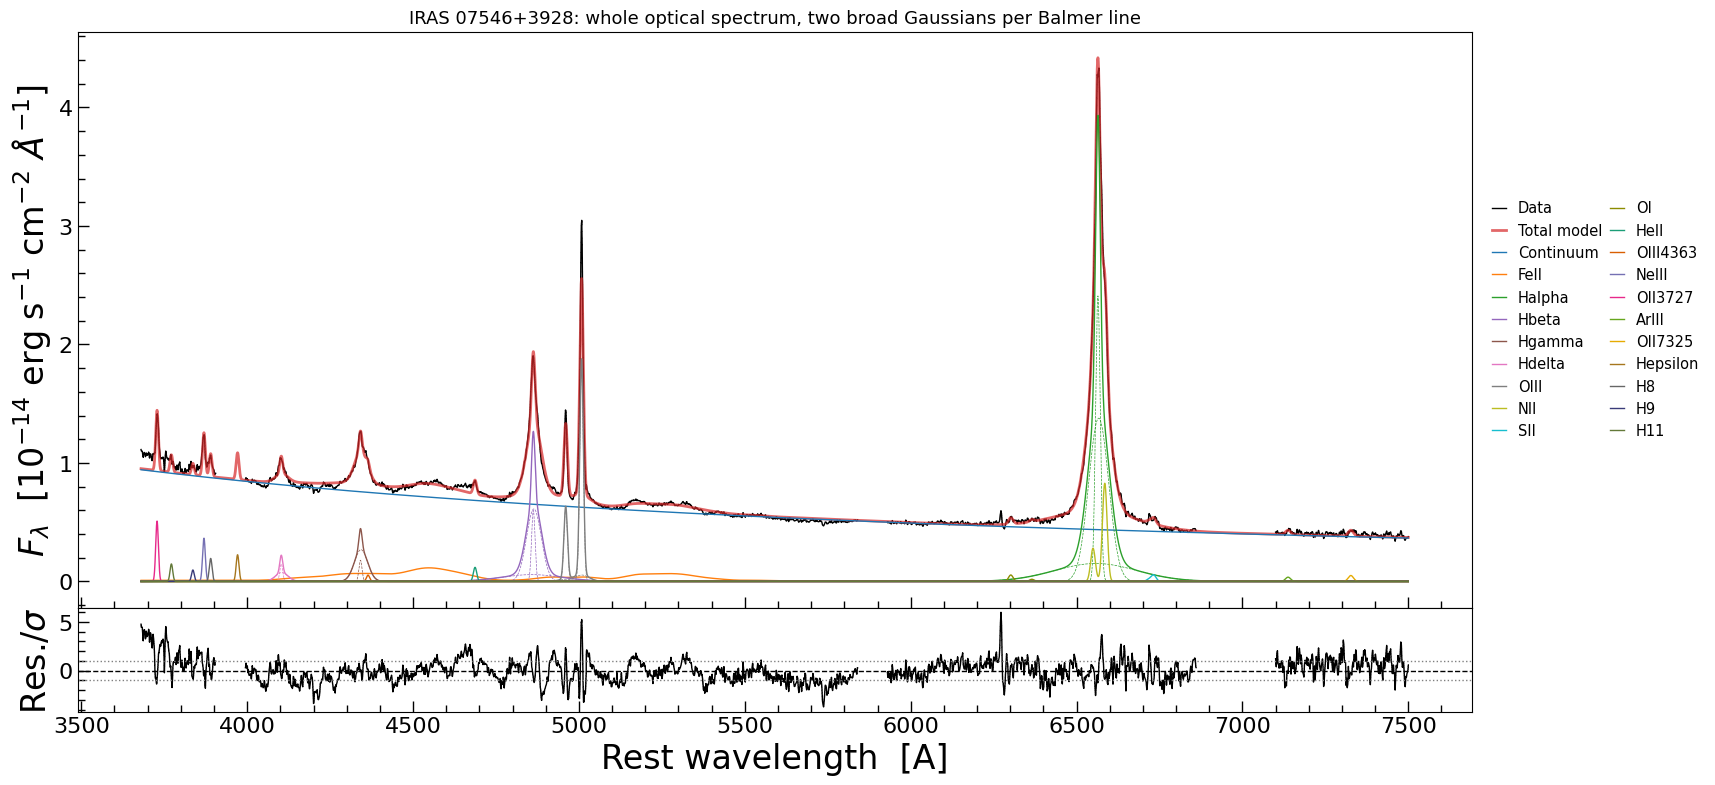

In [16]:
# residual_in_sigma divides by the error, so the panel shows "how many sigma" and
# a single bright pixel can no longer set the scale of the whole panel.
fig = plt.figure(figsize=(17.0, 8.0))
ax = fig.add_axes([0.055, 0.20, 0.82, 0.72])
axr = fig.add_axes([0.055, 0.07, 0.82, 0.13])
galspec.plot.plot_fit(
    wave, flux, model_cpu, ax=ax, axr=axr, mask_list=MASK_WINDOWS,
    error=error, residual_in_sigma=True,
    xlabel="Rest wavelength  [A]",
    ylabel=r"$F_\lambda$  [$10^{-14}$ erg s$^{-1}$ cm$^{-2}$ $\AA^{-1}$]",
    legend_kwargs={"fontsize": 10.5, "ncol": 2, "loc": "center left",
                   "bbox_to_anchor": (1.005, 0.5), "frameon": False})
ax.set_title("IRAS 07546+3928: whole optical spectrum, "
             "two broad Gaussians per Balmer line", fontsize=13)


### Zooms

The whole-spectrum figure is crowded; the same function, called on a wavelength
window, shows the components where they matter.


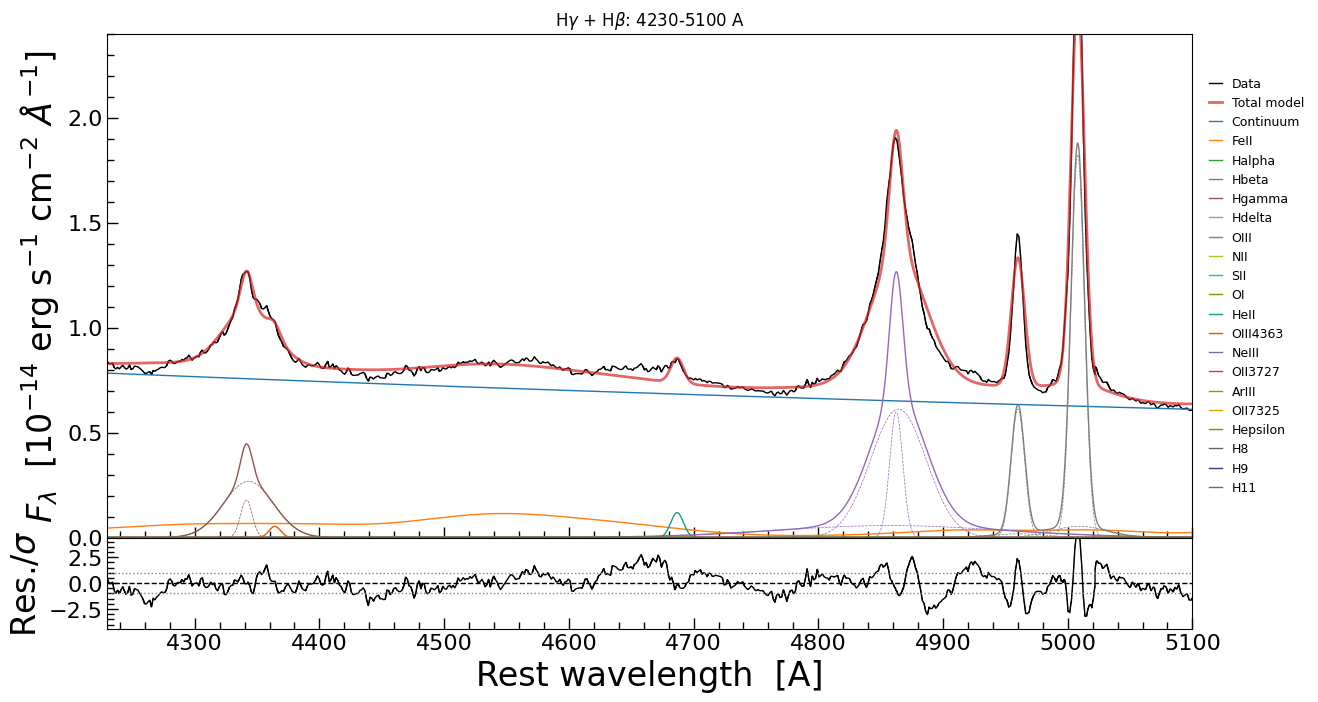

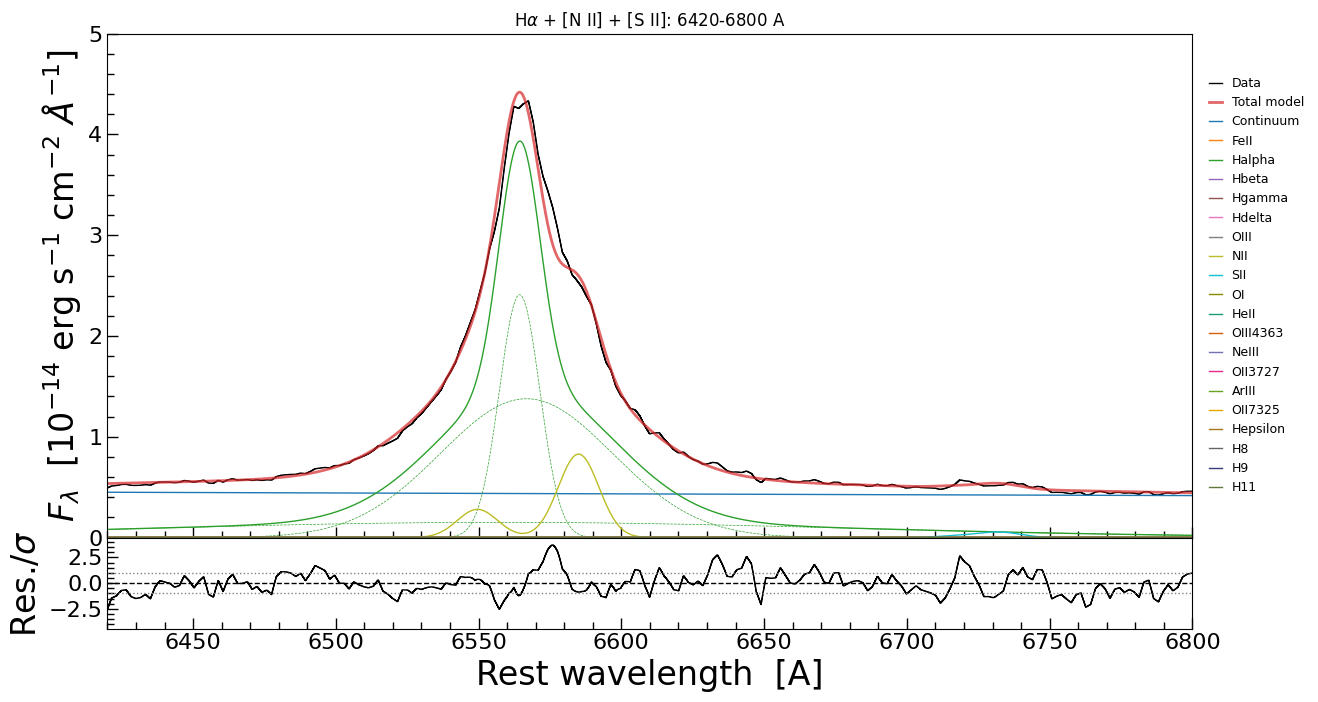

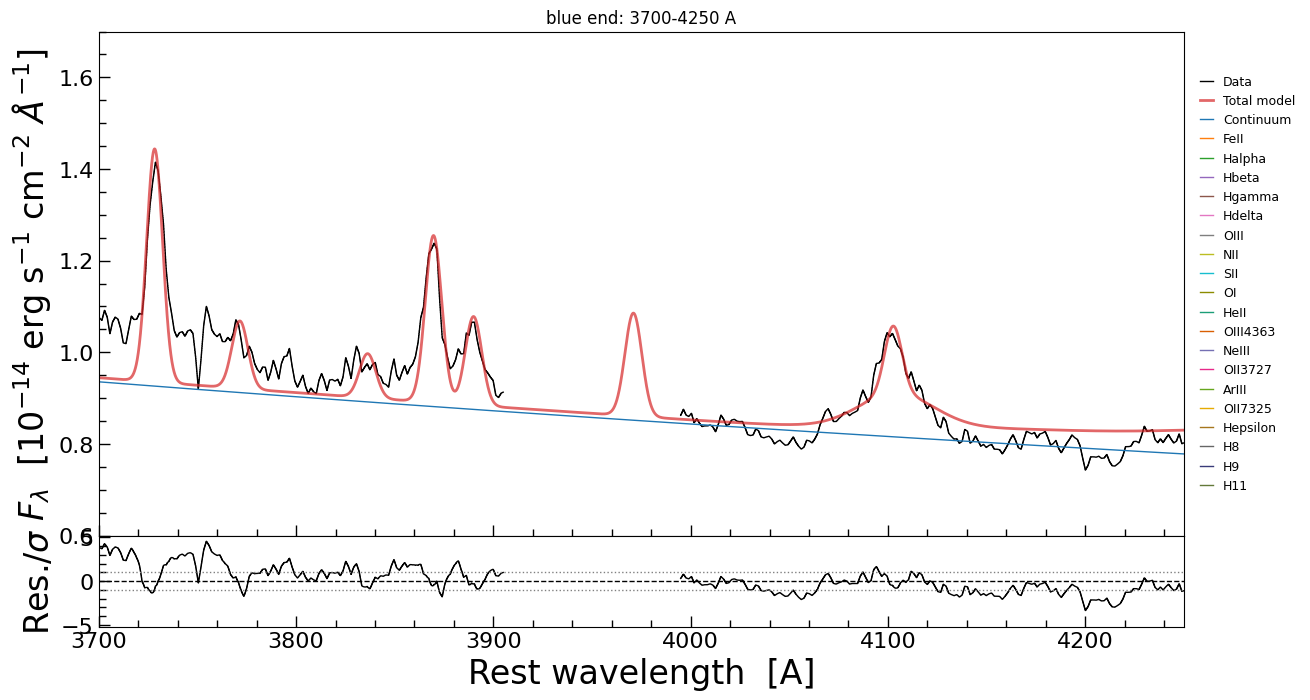

In [17]:
zooms = [("H$\\gamma$ + H$\\beta$", (4230, 5100), (0.0, 2.4)),
         ("H$\\alpha$ + [N II] + [S II]", (6420, 6800), (0.0, 5.0)),
         ("blue end", (3700, 4250), (0.6, 1.7))]


def residual_limits(wave, flux, error, model, xlim):
    """Residual limits for one panel, in sigma, from that panel's own scatter."""
    inside = (wave >= xlim[0]) & (wave <= xlim[1])
    residual = ((flux - np.asarray(model(wave))) / error)[inside]
    scale = float(np.nanpercentile(np.abs(residual), 99.5))
    return (-1.25 * scale - 0.06, 1.25 * scale + 0.06)


for title, xlim, ylim in zooms:
    fig = plt.figure(figsize=(15.5, 7.0))
    ax = fig.add_axes([0.06, 0.20, 0.70, 0.72])
    axr = fig.add_axes([0.06, 0.07, 0.70, 0.13])
    # The legend sits outside the axes: drawn inside, an opaque frame covered the
    # [O II] 3727 peak in the blue-end panel -- the one feature that panel exists
    # to show.
    galspec.plot.plot_fit(
        wave, flux, model_cpu, ax=ax, axr=axr, xlim=xlim, ylim0=ylim,
        ylim1=residual_limits(wave, flux, error, model_cpu, xlim),
        mask_list=MASK_WINDOWS, error=error, residual_in_sigma=True,
        xlabel="Rest wavelength  [A]",
        ylabel=r"$F_\lambda$  [$10^{-14}$ erg s$^{-1}$ cm$^{-2}$ $\AA^{-1}$]",
        legend_kwargs={"fontsize": 9.0, "ncol": 1, "loc": "center left",
                       "bbox_to_anchor": (1.005, 0.5), "frameon": False})
    ax.set_title(f"{title}: {xlim[0]:.0f}-{xlim[1]:.0f} A", fontsize=12)
    plt.show()


### Correlations

Nested sampling gives the full posterior, not just error bars. An elongated blob
means two parameters trade off against each other -- a broader component with a
smaller peak, say -- and quoting them independently would be misleading.


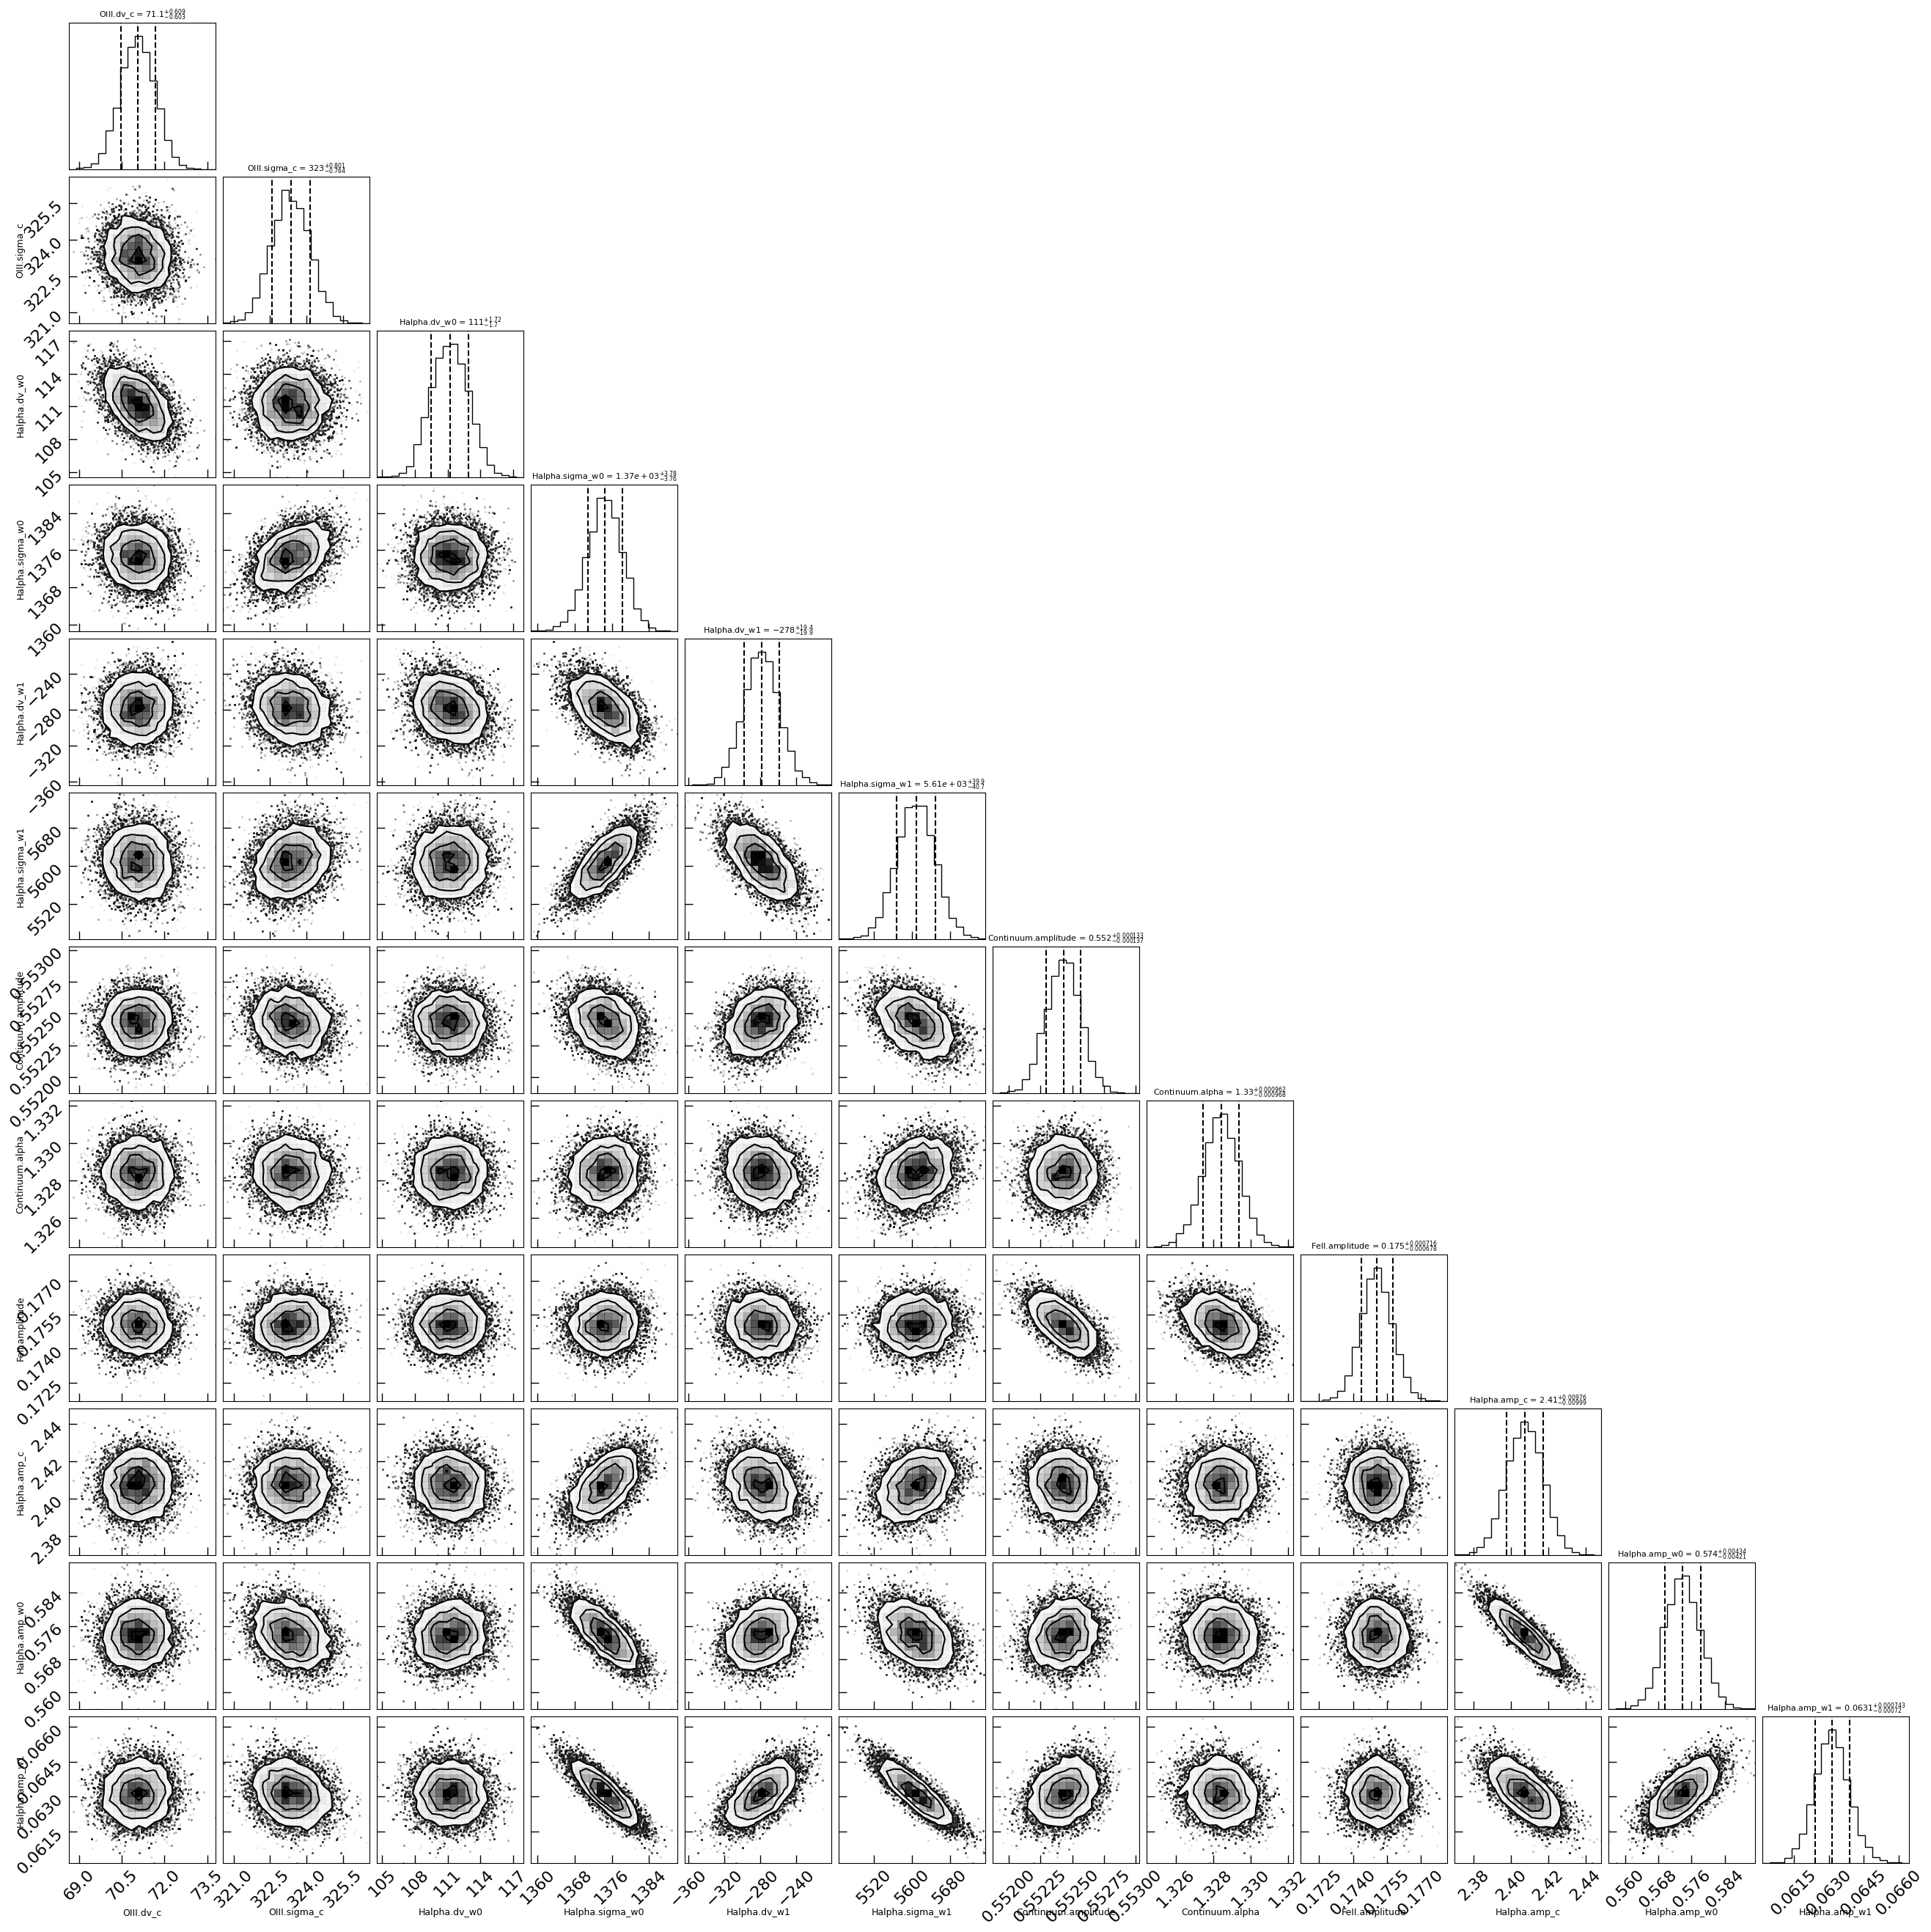

In [18]:
import corner

wanted = ["OIII.dv_c", "OIII.sigma_c", "Halpha.dv_w0", "Halpha.sigma_w0",
          "Halpha.dv_w1", "Halpha.sigma_w1", "Continuum.amplitude", "Continuum.alpha",
          "FeII.amplitude", "Halpha.amp_c", "Halpha.amp_w0", "Halpha.amp_w1"]
keep = [fit.full_param_names.index(name) for name in wanted
        if name in fit.full_param_names]
fig = corner.corner(fit.samples_equal_weight[:, keep],
                    labels=[fit.full_param_names[i] for i in keep],
                    quantiles=(0.16, 0.5, 0.84), show_titles=True, title_fmt=".3g",
                    title_kwargs={"fontsize": 8}, label_kwargs={"fontsize": 9})


## 9. What this does and does not show

* The blue end (3680-3780 A) is the weakest part of the model: no Balmer
  continuum, no host-galaxy stellar continuum, and heavily blended high-order
  Balmer lines. Trust the [O II] 3727 flux there less than the H-alpha region.
* The two broad Gaussians are a *description* of a profile, not a physical
  decomposition. Real broad-line profiles have longer wings than any Gaussian, so
  read them as "a broad part and a broader part" and treat their individual
  fluxes as indicative.
* Without the LSF folded in, the narrow widths include the instrument (~150 km/s
  FWHM, small next to ~700 km/s but not zero). Subtract it in quadrature if you
  need the gas kinematics alone.
* The narrow lines share one width by construction -- the standard assumption for
  forbidden-line regions, but it means a genuinely different narrow kinematics
  per line could not be detected.
* The [S II] ratio is measured, not assumed, because it is a density diagnostic:
  I(6716)/I(6731) near 1.3 means low-density gas, near 0.5 high-density. Turning
  it into an electron density needs a temperature and the atomic data, which is
  beyond a line-profile fit.
* The Fe II template width is fixed (degenerate with the continuum slope), and
  the Ca II H+K and Na D windows are down-weighted rather than modelled.
* The evidence (`log Z`) is only comparable between runs made with the same
  sampler.

## Where to go next

* `python fit_iras07546_jax.py` -- the same fit as a batch script.
* `python fit_iras07546_jax.py --quick` -- a rough answer in a few minutes.
* `docs/source/jax_gpu.rst` -- the CPU/GPU benchmark built on a fit like this.
* `tests/test_jax_parity.py` -- proves the JAX models equal the astropy ones.
* `tests/test_jax_io.py` -- proves the FITS round trip gives back the same fit.


## 10. Saving the fit so it can be reused

A nested-sampling run is expensive; the file should be the thing you keep. Two
files are written:

* `output/iras07546_jax_posterior.npz` -- a plain array dump, handy for a quick
  numpy read;
* `output/iras07546_jax_fit.fits` -- everything: the posterior samples, their
  unit-cube coordinates, the evidence and its error, the parameter names, bounds
  and priors, the sampler's convergence trajectory, the model description and the
  spectrum that was fitted.

The FITS layout is the one `galspec.dynesty_fit_io` already uses (`SAMPLES`,
`LOGWT`, `LOGL`, `LOGVOL`, `SAMPLES_EQ`, `PARAM_NAMES`, `PARAM_BOUNDS`,
`MODEL_PARAM`, `MODEL_STR`, ...), with three JNesty-only extensions: `SAMPLES_U`,
`DLZ_TRAJ` and `SCALE_TR`. The model is written by
`galspec.jax_models.serialization`, which records what a JAX model needs and an
astropy model does not -- the number of Gaussians per line, a template name or a
polynomial degree -- and the ties as *references* (`"OIII.dv_c"`), so they are
restored no matter how they were written in the code.


In [19]:
(EXAMPLE_DIR / "output").mkdir(exist_ok=True)
outfile = EXAMPLE_DIR / "output" / "iras07546_jax_posterior.npz"
np.savez_compressed(outfile,
                    samples=fit.samples_equal_weight,
                    parameter_names=np.array(fit.param_names),
                    qualified_names=np.array(fit.full_param_names),
                    log_evidence=fit.log_evidence,
                    log_evidence_error=fit.log_evidence_err,
                    wave=wave, flux=flux, error=error, predicted=predicted)
print(f"wrote {outfile}")

# The FITS file is the complete record of the fit: the samples (and their
# unit-cube coordinates), the evidence, the bounds, the sampler's convergence
# trajectory, the model itself and the data it was made against.
fits_out = EXAMPLE_DIR / "output" / "iras07546_jax_fit.fits"
save_jnesty_fit_to_fits(fit, fits_out)
print(f"wrote {fits_out}  ({fits_out.stat().st_size / 1e6:.1f} MB)")


wrote /home/shangguan/Softwares/my_modules/GalSpec/example/output/iras07546_jax_posterior.npz
JNesty_Fit object saved to /home/shangguan/Softwares/my_modules/GalSpec/example/output/iras07546_jax_fit.fits
wrote /home/shangguan/Softwares/my_modules/GalSpec/example/output/iras07546_jax_fit.fits  (85.1 MB)


### Reading it back

`load_jnesty_fit_from_fits` rebuilds the model and the fit, and every summary and
plot works on the result. The one thing it cannot rebuild is the prior
*transform*: `custom_priors` are Python callables and a closure cannot be written
to a file, so the file stores the resulting bounds and the names that had a
custom prior. A loaded fit is therefore for reading results, not for resuming the
sampler.


In [20]:
# Reading it back gives a JNesty_Fit with the same posterior, evidence, bounds and
# model -- and no sampler. This is the file worth keeping.
loaded = load_jnesty_fit_from_fits(fits_out)

print(f"log Z stored    {fit.log_evidence:12.2f} +/- {fit.log_evidence_err:.2f}")
print(f"log Z reloaded  {loaded.log_evidence:12.2f} +/- {loaded.log_evidence_err:.2f}")
print("same parameters:  ", list(loaded.param_names) == list(fit.param_names))
print("same posterior:   ",
      np.allclose(loaded.samples_equal_weight, fit.samples_equal_weight))

# everything the original object could do, it can do again
quantiles = loaded.get_quantiles((0.16, 0.5, 0.84))
print()
print(f"{'parameter':22s} {'16%':>10s} {'50%':>10s} {'84%':>10s}")
for index, name in enumerate(loaded.full_param_names[:6]):
    lo, mid, hi = quantiles[:, index]
    print(f"{name:22s} {lo:10.4g} {mid:10.4g} {hi:10.4g}")


JNesty_Fit object loaded from /home/shangguan/Softwares/my_modules/GalSpec/example/output/iras07546_jax_fit.fits
log Z stored       180531.41 +/- 0.70
log Z reloaded     180531.41 +/- 0.70
same parameters:   True


same posterior:    True

parameter                     16%        50%        84%
Continuum.amplitude        0.5523     0.5524     0.5526
Continuum.alpha             1.327      1.328      1.329
FeII.amplitude             0.1744      0.175     0.1758
Halpha.amp_c                2.397      2.407      2.417
Halpha.amp_w0              0.5696     0.5738     0.5782
Halpha.dv_w0                109.5      111.2      112.9


### Handing the GPU back

JNesty's device memory is dominated by one buffer that is allocated once at
`max_iterations` size (the dead-point history), plus the live set and the
compiled kernels. It does not grow from iteration to iteration, but an XLA
context never returns its high-water mark to the driver either, so a process that
has finished one fit keeps showing it in `nvidia-smi`. `release_device_buffers()`
drops the sampler and clears JAX's caches; the results, the model and the saved
files are untouched.


In [21]:
# The sampler still holds buffers on the GPU sized by max_iterations, and an XLA
# context never gives its high-water mark back to the driver. Everything so far
# lives in host memory (and in the two files), so hand the card back to other
# jobs; the results stay usable.
fit.release_device_buffers()
print("sampler released; quantiles still available:", fit.get_quantiles().shape)


sampler released; quantiles still available: (3, 38)
